In [1]:
##################################################################################################
# ATM 419/563
# mod_WRF_terrain.ipynb
# Megan Schiede, Fall 2026
#
# This script shows an example of how to modify terrain in geogrid_em.d01.nc  
# Can be used for modification of terrain for final projects
#
# geogrid_em.d01.nc has to be updated between each modification to bring back to inital state
# Does save a backup of geo_em.d01.nc
##################################################################################################

In [2]:
#Import xarray & matplotlib
import xarray as xr
import matplotlib.pyplot as plt

In [3]:
#Open file
path = './'
geogrid_file = 'geo_em.d01.nc'

In [4]:
ds = xr.open_dataset(path+geogrid_file)

In [5]:
#Write a backup of the original geogrid_file
ds.to_netcdf(path+'backup_'+geogrid_file)

In [6]:
### Modify terrain in this cell ###
scale_factor = 1000  # m

# Create an independent backup
ds_og = ds.copy(deep=True)

# Calculate new terrain values
new_HGT = ds_og['HGT_M'].values + scale_factor

# Replace HGT_M in the dataset
ds['HGT_M'].values[:] = new_HGT

In [7]:
##Check Mean Values
print('Original HGT_M mean:', ds_og['HGT_M'].mean().values)
print('Modified HGT_M mean:', ds['HGT_M'].mean().values)
print('Difference in mean:', (ds['HGT_M'] - ds_og['HGT_M']).mean().values)

Original HGT_M mean: 70.724853515625
Modified HGT_M mean: 1070.723876953125
Difference in mean: 1000.0


In [8]:
#Save new version of file
#Overwrites original file from geogrid
ds.to_netcdf(path+'mod_'+geogrid_file)

In [9]:
#In the terminal, run the following command
#Overwrites original 
''' cp mod_geo_em.d01.nc geo_em.d01.nc '''

#Restores original
''' cp backup_geo_em.d01.nc geo_em.d01.nc'''

' cp backup_geo_em.d01.nc geo_em.d01.nc'

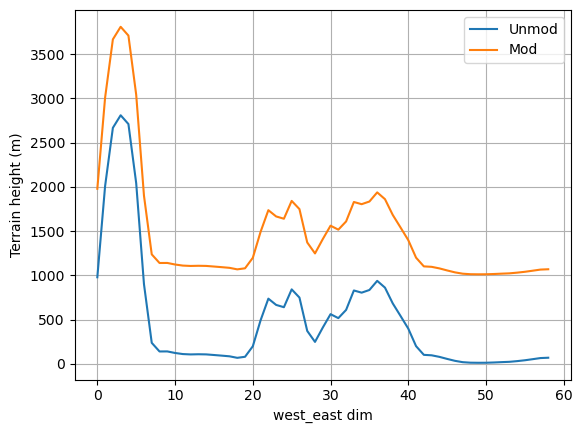

In [10]:
##Cross section of terrain height along west_east dim
##Assume south_north=0; can be modified
#For inital terrain height
ds_og_plot = ds_og.isel(Time=0).isel(south_north=0)
#For modified terrain height
ds_mod_plot = ds.isel(Time=0).isel(south_north=0)

plt.plot(ds_og_plot.west_east, ds_og_plot.HGT_M, label='Unmod')
plt.plot(ds_mod_plot.west_east, ds_mod_plot.HGT_M, label='Mod')

plt.ylabel('Terrain height (m)')
plt.xlabel('west_east dim')
plt.legend()
plt.grid(True)

plt.show()

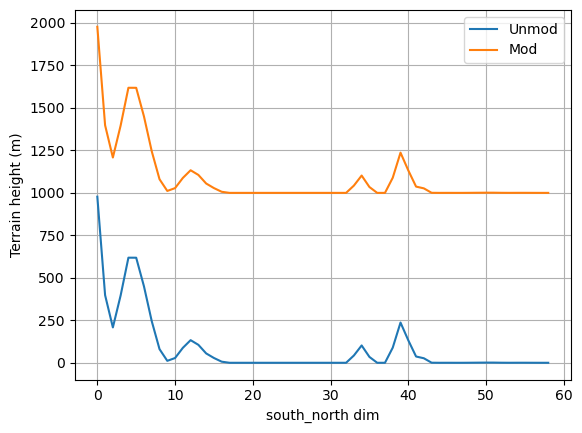

In [11]:
##Cross section of terrain height along south_north dim 
##Assume west_east=0; can be modified
#For inital terrain height
ds_og_plot = ds_og.isel(Time=0).isel(west_east=0)
#For modified terrain height
ds_mod_plot = ds.isel(Time=0).isel(west_east=0)

plt.plot(ds_og_plot.south_north, ds_og_plot.HGT_M, label='Unmod')
plt.plot(ds_mod_plot.south_north, ds_mod_plot.HGT_M, label='Mod')

plt.ylabel('Terrain height (m)')
plt.xlabel('south_north dim')
plt.legend()
plt.grid(True)

plt.show()